In [36]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, Ridge
from xgboost import XGBRegressor
from sklearn.metrics import root_mean_squared_error

## EDA

In [3]:
df = pd.read_csv("diversified_ecommerce_dataset.csv", nrows = 100000)
df.head()

,Product ID,Product Name,Category,Price,Discount,Tax Rate,Stock Level,Supplier ID,Customer Age Group,Customer Location,Customer Gender,Shipping Cost,Shipping Method,Return Rate,Seasonality,Popularity Index
0,P6879,Jacket,Apparel,53.85,5,15,150,S535,35-44,"New York, USA",Male,23.32,Standard,4.49,Yes,56
1,P5132,Camera,Electronics,761.26,10,15,224,S583,25-34,"London, UK",Female,20.88,Overnight,16.11,No,79
2,P2941,Sneakers,Footwear,1756.76,5,8,468,S118,25-34,"Tokyo, Japan",Non-Binary,16.43,Standard,4.93,No,40
3,P8545,Cookbooks,Books,295.24,10,15,25,S104,18-24,"Paris, France",Female,27.49,Standard,1.31,No,93
4,P4594,Camera,Electronics,832.00,10,12,340,S331,55+,"Tokyo, Japan",Male,45.93,Overnight,4.37,No,56


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 16 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Product ID          100000 non-null  object 
 1   Product Name        100000 non-null  object 
 2   Category            100000 non-null  object 
 3   Price               100000 non-null  float64
 4   Discount            100000 non-null  int64  
 5   Tax Rate            100000 non-null  int64  
 6   Stock Level         100000 non-null  int64  
 7   Supplier ID         100000 non-null  object 
 8   Customer Age Group  100000 non-null  object 
 9   Customer Location   100000 non-null  object 
 10  Customer Gender     100000 non-null  object 
 11  Shipping Cost       100000 non-null  float64
 12  Shipping Method     100000 non-null  object 
 13  Return Rate         100000 non-null  float64
 14  Seasonality         100000 non-null  object 
 15  Popularity Index    100000 non-null

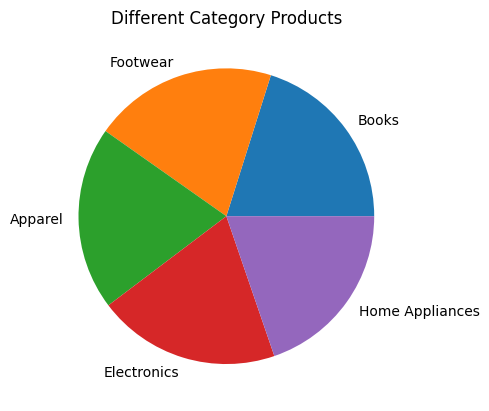

In [5]:
plt.pie(df["Category"].value_counts(),labels = df["Category"].value_counts().index)
plt.title("Different Category Products")
plt.show()

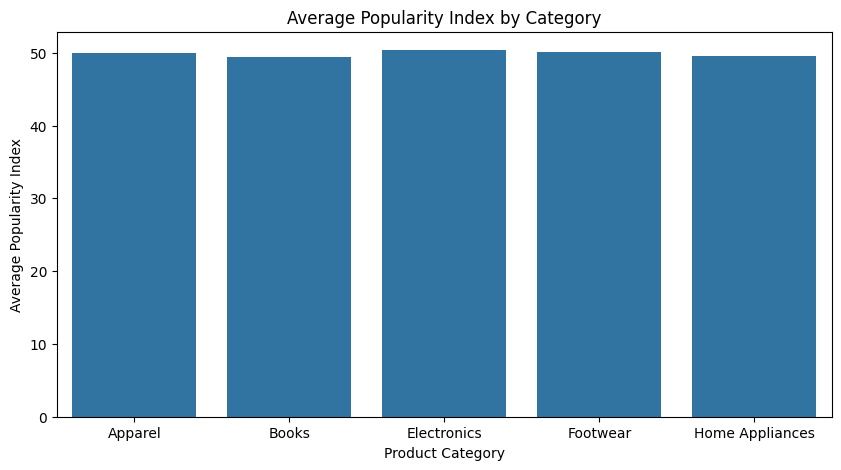

In [39]:
category_popularity = df.groupby("Category")["Popularity Index"].mean()

plt.figure(figsize=(10, 5))
sns.barplot(
    x=category_popularity.index,
    y=category_popularity.values
)
plt.title("Average Popularity Index by Category")
plt.xlabel("Product Category")
plt.ylabel("Average Popularity Index")
plt.show()

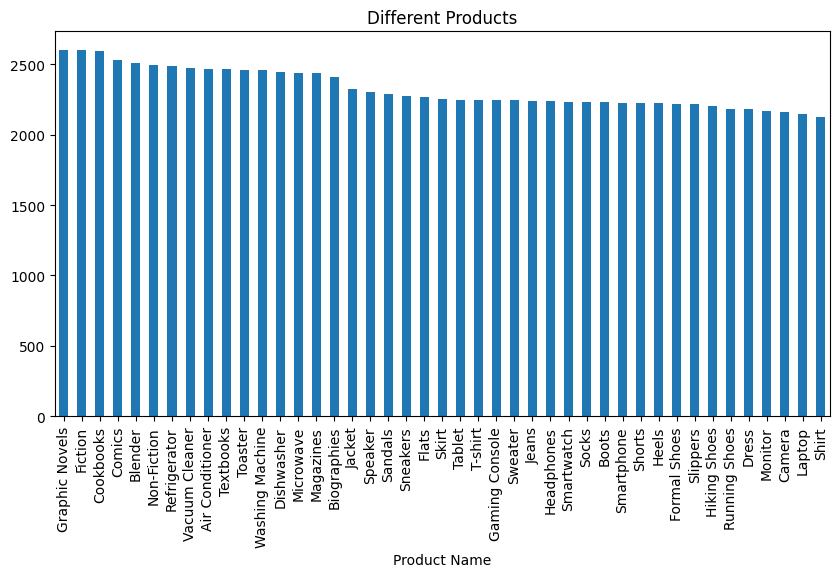

In [6]:
plt.figure(figsize=(10,5))
df["Product Name"].value_counts().plot(kind="bar")
plt.title("Different Products")
plt.show()

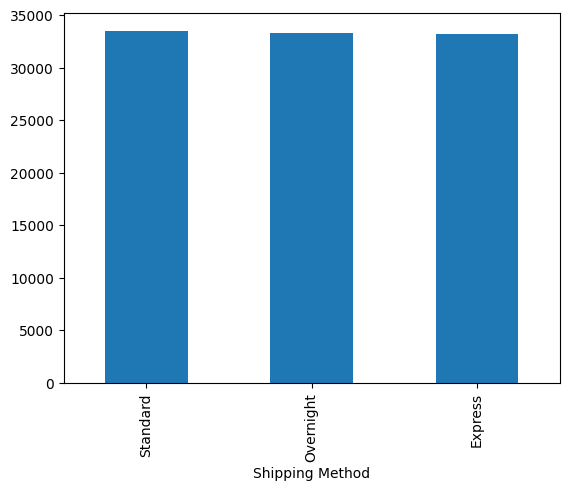

In [7]:
df["Shipping Method"].value_counts().plot(kind="bar")
plt.show()

In [8]:
df["Customer Location"].value_counts()

Customer Location
Mumbai, India              6775
Dubai, UAE                 6771
Tokyo, Japan               6753
Houston, USA               6714
Singapore                  6713
Cape Town, South Africa    6707
New York, USA              6673
Paris, France              6657
Phoenix, USA               6655
Berlin, Germany            6650
Los Angeles, USA           6645
Chicago, USA               6620
Toronto, Canada            6595
Sydney, Australia          6543
London, UK                 6529
Name: count, dtype: int64

In [9]:
# Null values
df.isnull().sum()

Product ID            0
Product Name          0
Category              0
Price                 0
Discount              0
Tax Rate              0
Stock Level           0
Supplier ID           0
Customer Age Group    0
Customer Location     0
Customer Gender       0
Shipping Cost         0
Shipping Method       0
Return Rate           0
Seasonality           0
Popularity Index      0
dtype: int64

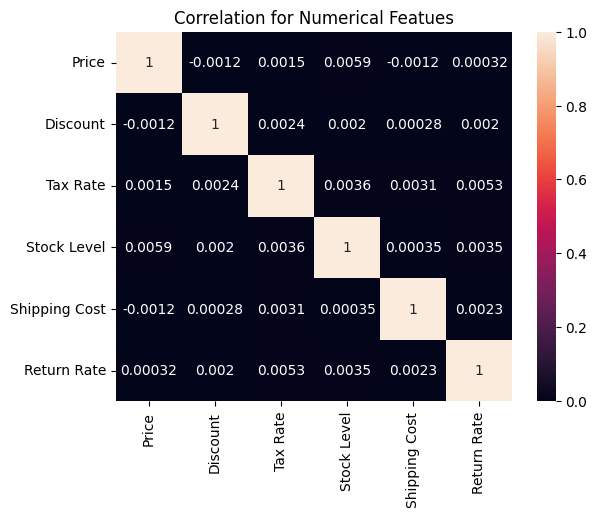

In [42]:
# Correlation
num_columns = X.select_dtypes(exclude=object).corr()
sns.heatmap(num_columns, annot=True)
plt.title("Correlation for Numerical Featues")
plt.show()

## Preprocessing

In [10]:
X = df.drop(columns=["Product ID","Supplier ID","Popularity Index"])
y = df["Popularity Index"]

In [11]:
num_columns = X.select_dtypes(exclude=object).columns
cat_columns = X.select_dtypes(include=object).columns

In [12]:
# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y , test_size=0.2, random_state=42)

In [13]:
numerical_transformer = Pipeline([
    ("scalar",StandardScaler())
])
categorical_transformer = Pipeline([
    ("onehot",OneHotEncoder(handle_unknown="ignore"))
])

In [14]:
preprocess = ColumnTransformer(
    transformers=[
        ("num",numerical_transformer, num_columns),
        ("cat", categorical_transformer, cat_columns)
    ]
)

# Models

## Linear Regression

In [15]:
lr_model = make_pipeline(
    preprocess,
    LinearRegression()
)

In [16]:
lr_model.fit(X_train, y_train)

,steps,"[('columntransformer', ...), ('linearregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [17]:
print(f"R2 score: {lr_model.score(X_train, y_train):.6f}")

R2 score: 0.000876


In [18]:
y_test_pred = lr_model.predict(X_test)

print(f"Root Mean Squared Error: {root_mean_squared_error(y_test, y_test_pred)}")

Root Mean Squared Error: 29.223423483248887


## Polynomial Regression

In [23]:
numerical_transformer = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(
        degree=4,
        include_bias=False
    )),
    ("poly_scaler", StandardScaler())
])
preprocess = ColumnTransformer(
    transformers=[
        ("num",numerical_transformer, num_columns),
        ("cat", categorical_transformer, cat_columns)
    ]
)

In [24]:
poly_lr_model = make_pipeline(
    preprocess,
    Ridge(alpha=1.0, solver="lsqr")
)

In [25]:
poly_lr_model.fit(X_train, y_train)

,steps,"[('columntransformer', ...), ('ridge', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [26]:
print(f"R2 score: {poly_lr_model.score(X_train, y_train):.6f}")
y_test_pred = poly_lr_model.predict(X_test)
print(f"Root Mean Squared Error: {root_mean_squared_error(y_test, y_test_pred)}")

R2 score: 0.003662
Root Mean Squared Error: 29.26051050055448


## XGBoost

In [28]:
preprocess = ColumnTransformer(
    transformers=[
        ("num","passthrough", num_columns),
        ("cat", categorical_transformer, cat_columns)
    ]
)

In [29]:
xgb_model = make_pipeline(
    preprocess,
    XGBRegressor()
)

In [30]:
xgb_model.fit(X_train, y_train)

,steps,"[('columntransformer', ...), ('xgbregressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [31]:
print(f"R2 score: {xgb_model.score(X_train, y_train):.6f}")
y_test_pred = xgb_model.predict(X_test)
print(f"Root Mean Squared Error: {root_mean_squared_error(y_test, y_test_pred)}")

R2 score: 0.152816
Root Mean Squared Error: 29.617759704589844
